## Step 9: Economic Layer

In [1]:
import pandas as pd
import numpy as np
import sys
import json
import os

import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from metrics import *

# Load raw train and test data
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

# Load engineered features
ft_tr = pd.read_csv("../data/features_train.csv")
ft_te = pd.read_csv("../data/features_test.csv")

# Separate predictors and target
X_train = ft_tr.drop(columns="DEFAULT")
y_train = ft_tr["DEFAULT"].values

X_test = ft_te.drop(columns="DEFAULT")

# Load saved test predictions
pred = pd.read_csv("../reports/test_predictions.csv")

# Check required model files
print("SCORECARD OOF FILE:",
      os.path.exists("../models/oof_scorecard.npy"))

print("LIGHTGBM OOF FILE:",
      os.path.exists("../models/oof_lgbm.npy"))

print("CALIBRATED LIGHTGBM OOF FILE:",
      os.path.exists("../models/oof_lgbm_cal.npy"))

print("\nTEST PREDICTION COLUMNS:")
print(pred.columns.tolist())

print("\nDATA SHAPES:")
print("Train:", train.shape)
print("Test:", test.shape)
print("Train features:", X_train.shape)
print("Test features:", X_test.shape)
print("Test predictions:", pred.shape)

SCORECARD OOF FILE: False
LIGHTGBM OOF FILE: False
CALIBRATED LIGHTGBM OOF FILE: False

TEST PREDICTION COLUMNS:
['y', 'p_sc', 'credit_score', 'p_gb', 'SEX', 'MARRIAGE']

DATA SHAPES:
Train: (21000, 24)
Test: (9000, 24)
Train features: (21000, 49)
Test features: (9000, 49)
Test predictions: (9000, 6)


In [2]:
# Load the actual OOF file created in Step 8
oof = pd.read_csv("../reports/oof_predictions.csv")

# Extract the target and model probabilities
oof_y = oof["DEFAULT"].values
oof_sc = oof["Scorecard"].values
oof_gb = oof["C3_Monotonic_LightGBM"].values

# Extract saved test predictions
y_te = pred["y"].values
p_sc = pred["p_sc"].values
p_gb = pred["p_gb"].values
score_te = pred["credit_score"].values

# Check that the OOF and test data align
assert len(oof_y) == len(y_train)
assert len(oof_sc) == len(oof_y)
assert len(oof_gb) == len(oof_y)
assert len(y_te) == len(test)
assert len(p_sc) == len(y_te)
assert len(p_gb) == len(y_te)
assert len(score_te) == len(y_te)

print("OOF shape:", oof.shape)
print("Scorecard OOF:", len(oof_sc))
print("C3 LightGBM OOF:", len(oof_gb))
print("Test predictions:", len(y_te))

print("\nOOF mean PD:",
      round(oof_sc.mean(), 4),
      round(oof_gb.mean(), 4),
      "| Train default:",
      round(y_train.mean(), 4))

print("\nTest mean PD:",
      round(p_sc.mean(), 4),
      round(p_gb.mean(), 4),
      "| Test default:",
      round(y_te.mean(), 4))

OOF shape: (21000, 5)
Scorecard OOF: 21000
C3 LightGBM OOF: 21000
Test predictions: 9000

OOF mean PD: 0.2212 0.2212 | Train default: 0.2212

Test mean PD: 0.2202 0.2206 | Test default: 0.2212


In [3]:
print(
    "Scorecard config exists:",
    os.path.exists("../models/scorecard_config.json")
)

Scorecard config exists: True


In [4]:
# Load the scorecard configuration
with open("../models/scorecard_config.json", "r") as f:
    cfg = json.load(f)

# Extract the score scaling values
factor = cfg["factor"]
offset = cfg["offset"]

print("Factor:", factor)
print("Offset:", offset)

Factor: 28.85390081777927
Offset: 487.1228762045055


In [5]:
#Define the economic assumptions
# Scenario A: Flat customer economics

R_flat = 6000.0       # Revenue from a good customer (NT$)
LGD = 0.70            # Loss given default: 70%

# Estimate exposure using training data only
EAD_flat = train["BILL_AMT1"].clip(lower=0).mean()

# Expected loss if a customer defaults
L_flat = LGD * EAD_flat

# Break-even probability of default
p_star = R_flat / (R_flat + L_flat)

print(f"Revenue (R): NT$ {R_flat:,.2f}")
print(f"LGD: {LGD:.0%}")
print(f"Estimated EAD: NT$ {EAD_flat:,.2f}")
print(f"Loss on default (L): NT$ {L_flat:,.2f}")
print(f"Revenue / Loss: {R_flat / L_flat:.3f}")
print(f"Break-even PD: {p_star:.3%}")

Revenue (R): NT$ 6,000.00
LGD: 70%
Estimated EAD: NT$ 51,221.26
Loss on default (L): NT$ 35,854.88
Revenue / Loss: 0.167
Break-even PD: 14.335%


In [6]:
#Calculate approve-all expected profit
# Training default rate
pbar = y_train.mean()

# Expected profit per customer if everyone is approved
approve_all_profit = R_flat - pbar * (R_flat + L_flat)

# Revenue required for approve-all to break even
break_even_revenue = pbar * L_flat / (1 - pbar)

print("Training default rate:", f"{pbar:.3%}")
print("Approve-all expected profit per customer:",
      f"NT$ {approve_all_profit:,.2f}")
print("Break-even revenue for approve-all:",
      f"NT$ {break_even_revenue:,.2f}")

Training default rate: 22.119%
Approve-all expected profit per customer: NT$ -3,257.90
Break-even revenue for approve-all: NT$ 10,183.18


Under the current assumption of NT$6,000 revenue, approving everyone produces an expected loss. The break-even revenue is higher than the assumed revenue, so we need to identify customers whose predicted PD is sufficiently low to make approval economically worthwhile.

In [7]:
# Convert break-even PD into a scorecard cutoff
score_cut = offset - factor * np.log(p_star / (1 - p_star))

print("Break-even PD:", f"{p_star:.3%}")
print("Scorecard cutoff:", round(score_cut, 2))
print("Decision rule: Approve if score >=", round(score_cut, 2))

Break-even PD: 14.335%
Scorecard cutoff: 538.71
Decision rule: Approve if score >= 538.71


In [8]:
#Test the profit engine
from economics import *

# Small example with four customers
y = np.array([0, 0, 1, 0])
p = np.array([0.05, 0.10, 0.50, 0.20])

# Revenue = 100, Loss = 900
g = profit_grid(y, p, 100, 900, [0.05, 0.10, 0.20, 0.50])

print("Profit grid (total profit at each cutoff):")
print(g["profit_pc"].values * 4)

print("\nProfit when cutoff is 0.20:")
print(evaluate(y, p <= 0.2, 100, 900)["profit_total"])

print("\nProfit decomposition:")
print(decompose(y, p <= 0.2, 100, 900))

print("\nProfit when everyone is approved:")
print(evaluate(y, np.ones(4, bool), 100, 900)["profit_total"])

Profit grid (total profit at each cutoff):
[ 100.  200.  300. -600.]

Profit when cutoff is 0.20:
300.0

Profit decomposition:
{'losses_avoided': np.int64(900), 'revenue_foregone': np.int64(0), 'net_gain_vs_approve_all': np.int64(900)}

Profit when everyone is approved:
-600.0


In [9]:
#Profit curves and optimal cutoff
# Step 9.5A: Profit curves on training OOF predictions

y_train = train["DEFAULT"].values

cuts = np.round(np.arange(0.02, 0.60, 0.005), 3)

g_sc = profit_grid(y_train, oof_sc, R_flat, L_flat, cuts)
g_gb = profit_grid(y_train, oof_gb, R_flat, L_flat, cuts)

# Smooth the profit curves to reduce small fluctuations
for g in (g_sc, g_gb):
    g["smooth"] = g["profit_pc"].rolling(
        5, center=True, min_periods=1
    ).mean()

print("Scorecard profit curve:")
print(g_sc.head())

print("\nLightGBM profit curve:")
print(g_gb.head())

print("\nNumber of cutoffs:", len(cuts))

Scorecard profit curve:
     cut  approve_rate  profit_pc     smooth
0  0.020      0.000000   0.000000   0.095238
1  0.025      0.000000   0.000000   1.000000
2  0.030      0.000048   0.285714   3.085714
3  0.035      0.000619   3.714286   8.287096
4  0.040      0.001905  11.428571  22.864053

LightGBM profit curve:
     cut  approve_rate  profit_pc      smooth
0  0.020      0.000000   0.000000    1.526113
1  0.025      0.000000   0.000000    8.938937
2  0.030      0.001095   4.578339   25.967734
3  0.035      0.006857  31.177409   61.029475
4  0.040      0.019667  94.082924  117.946047

Number of cutoffs: 116


In [10]:
# 9.5B — Find the optimum cutoff and plateau
def optimum(g, tol=0.02):
    best = g.loc[g["smooth"].idxmax()]
    plateau = g[g["smooth"] >= best["smooth"] - tol*abs(best["smooth"])]
    return best, plateau["cut"].min(), plateau["cut"].max()


for name, g in [("Scorecard", g_sc), ("LightGBM", g_gb)]:
    b, lo, hi = optimum(g)
    print(
        f"{name}: empirical optimum cutoff {b['cut']:.3f} | "
        f"plateau [{lo:.3f}, {hi:.3f}] | "
        f"theory p* {p_star:.3f} | "
        f"approval {b['approve_rate']:.1%} | "
        f"profit/customer {b['smooth']:,.0f}"
    )

Scorecard: empirical optimum cutoff 0.130 | plateau [0.120, 0.155] | theory p* 0.143 | approval 48.5% | profit/customer 1,026
LightGBM: empirical optimum cutoff 0.130 | plateau [0.115, 0.150] | theory p* 0.143 | approval 45.5% | profit/customer 1,158


The theoretical break-even PD of 14.3% lies inside both empirical plateaus.

Therefore, we can use the theoretical break-even cutoff of 0.143 for both models. This is preferable to choosing an exact empirical maximum because nearby cutoffs produce almost the same profit.

In [11]:
#9.5C — Check OOF probability calibration
print("Actual training default rate:", round(y_train.mean(), 4))
print("Scorecard mean OOF PD:", round(oof_sc.mean(), 4))
print("LightGBM mean OOF PD:", round(oof_gb.mean(), 4))
print("Theoretical break-even PD:", round(p_star, 4))

Actual training default rate: 0.2212
Scorecard mean OOF PD: 0.2212
LightGBM mean OOF PD: 0.2212
Theoretical break-even PD: 0.1434


In [12]:
#9.5D — Bootstrap uncertainty of the optimum cutoff
rng = np.random.default_rng(9)
opt = []

for _ in range(300):
    i = rng.integers(0, len(y_train), len(y_train))

    gg = profit_grid(
        y_train[i],
        oof_sc[i],
        R_flat,
        L_flat,
        cuts
    )

    gg["s"] = gg["profit_pc"].rolling(
        5, center=True, min_periods=1
    ).mean()

    opt.append(gg.loc[gg["s"].idxmax(), "cut"])

print(
    "Bootstrap optimum cutoff, 95% interval:",
    np.percentile(opt, [2.5, 97.5])
)

Bootstrap optimum cutoff, 95% interval: [0.12  0.155]


This means the estimated profit-maximising cutoff varies between 12.0% and 15.5% across bootstrap samples.

Our theoretical break-even cutoff of 14.34% lies inside this interval.

This supports retaining 14.34% rather than relying on one exact empirical optimum of 13%.

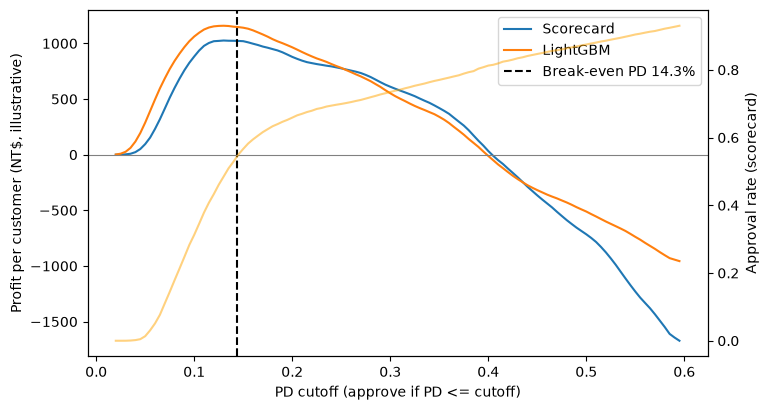

In [13]:
#9.5E — Plot the profit curves
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(g_sc["cut"], g_sc["smooth"], label="Scorecard")
ax.plot(g_gb["cut"], g_gb["smooth"], label="LightGBM")

ax.axvline(
    p_star,
    color="k",
    ls="--",
    label=f"Break-even PD {p_star:.1%}"
)

ax.axhline(0, color="grey", lw=0.8)

ax.set_xlabel("PD cutoff (approve if PD <= cutoff)")
ax.set_ylabel("Profit per customer (NT$, illustrative)")

ax2 = ax.twinx()
ax2.plot(
    g_sc["cut"],
    g_sc["approve_rate"],
    color="orange",
    alpha=0.5
)
ax2.set_ylabel("Approval rate (scorecard)")

ax.legend()

plt.savefig(
    "../reports/figures/profit_vs_cutoff.png",
    bbox_inches="tight"
)

plt.show()

In [14]:
#9.5F — Find the accuracy-maximising cutoff
agrid = np.arange(0.2, 0.8, 0.01)

t_acc = agrid[
    int(np.argmax([
        ((oof_sc > t) == y_train).mean()
        for t in agrid
    ]))
]

print("Accuracy-maximizing cutoff:", round(t_acc, 2))

Accuracy-maximizing cutoff: 0.51


In [15]:
#9.6 — Evaluate strategies on the test dataset
#9.6A — Evaluate strategies on the test dataset
R, L = R_flat, L_flat

strategies = {
    "Approve everyone": np.ones(len(y_te), bool),

    "Decline everyone": np.zeros(len(y_te), bool),

    f"Accuracy cutoff (PD<={t_acc:.2f})": p_sc <= t_acc,

    "Policy rule: decline if 2+ months late":
        X_test["delay_latest"].values < 2,

    f"Scorecard @ break-even ({p_star:.1%})":
        p_sc <= p_star,

    f"LightGBM @ break-even ({p_star:.1%})":
        p_gb <= p_star,

    "Perfect foresight (ceiling)": y_te == 0,
}

rows = {
    n: evaluate(y_te, m, R, L)
    for n, m in strategies.items()
}

strat = pd.DataFrame(rows).T

strat["profit_per_1000_cust"] = (
    1000 * strat["profit_per_customer"]
)

strat["share_of_ceiling_%"] = (
    100 * strat["profit_total"] /
    strat.loc[
        "Perfect foresight (ceiling)",
        "profit_total"
    ]
)

strat.round(3)

,approval_rate,bad_rate_approved,profit_total,profit_per_customer,profit_per_1000_cust,share_of_ceiling_%
Approve everyone,1.000,0.221,-2.933307e+07,-3259.230,-3259230.162,-69.751
Decline everyone,0.000,NaN,0.000000e+00,0.000,0.000,0.000
Accuracy cutoff (PD<=0.51),0.882,0.170,-8.959801e+06,-995.533,-995533.490,-21.305
Policy rule: decline if 2+ months late,0.896,0.167,-7.946672e+06,-882.964,-882963.568,-18.896
Scorecard @ break-even (14.3%),0.547,0.105,7.887026e+06,876.336,876336.183,18.755
LightGBM @ break-even (14.3%),0.505,0.092,9.684949e+06,1076.105,1076105.474,23.030
Perfect foresight (ceiling),0.779,0.000,4.205400e+07,4672.667,4672666.667,100.000


In [16]:
print("APPROVAL RATE TRANSFER CHECK")
print("--------------------------------")

print("Scorecard OOF:",
      round((oof_sc <= p_star).mean(), 4))

print("Scorecard Test:",
      round((p_sc <= p_star).mean(), 4))

print()

print("LightGBM OOF:",
      round((oof_gb <= p_star).mean(), 4))

print("LightGBM Test:",
      round((p_gb <= p_star).mean(), 4))

APPROVAL RATE TRANSFER CHECK
--------------------------------
Scorecard OOF: 0.5441
Scorecard Test: 0.5468

LightGBM OOF: 0.5079
LightGBM Test: 0.5049


In [17]:
#9.6B — Paired bootstrap confidence intervals
P = pd.DataFrame({
    n: np.where(m, realized_profit(y_te, R, L), 0.0)
    for n, m in strategies.items()
})

rng = np.random.default_rng(2026)

idx = rng.integers(
    0, len(y_te),
    size=(2000, len(y_te))
)

def boot_mean(v):
    return v[idx].mean(axis=1)


sc_k = [
    k for k in P.columns if k.startswith("Scorecard")
][0]

gb_k = [
    k for k in P.columns if k.startswith("LightGBM")
][0]

ac_k = [
    k for k in P.columns if k.startswith("Accuracy")
][0]


comparisons = {
    "Scorecard - approve all":
        P[sc_k] - P["Approve everyone"],

    "Scorecard - accuracy cutoff":
        P[sc_k] - P[ac_k],

    "Scorecard - policy rule":
        P[sc_k] - P["Policy rule: decline if 2+ months late"],

    "LightGBM - scorecard":
        P[gb_k] - P[sc_k],
}


out = {
    n: np.percentile(
        boot_mean(v.values),
        [2.5, 50, 97.5]
    )
    for n, v in comparisons.items()
}

pd.DataFrame(
    out,
    index=["low", "median", "high"]
).T.round(1)


,low,median,high
Scorecard - approve all,3856.5,4141.6,4437.1
Scorecard - accuracy cutoff,1641.2,1875.2,2121.6
Scorecard - policy rule,1526.2,1763.2,1993.7
LightGBM - scorecard,87.4,201.1,313.4


In [18]:
#9.6C — Profit decomposition
pd.DataFrame({
    k: decompose(y_te, strategies[k], R, L)
    for k in [sc_k, gb_k, ac_k]
}).T.round(0)

,losses_avoided,revenue_foregone,net_gain_vs_approve_all
Scorecard @ break-even (14.3%),52850097.0,15630000.0,37220097.0
LightGBM @ break-even (14.3%),56328021.0,17310000.0,39018021.0
Accuracy cutoff (PD<=0.51),22911270.0,2538000.0,20373270.0


In [19]:
#9.6D — Prepare bootstrap confidence intervals
profit_ci = {}

for name in P.columns:
    vals = boot_mean(P[name].values)
    profit_ci[name] = np.percentile(vals, [2.5, 50, 97.5])

profit_ci = pd.DataFrame(
    profit_ci,
    index=["low", "median", "high"]
).T

profit_ci.round(2)

,low,median,high
Approve everyone,-3626.74,-3263.88,-2924.27
Decline everyone,0.00,0.00,0.00
Accuracy cutoff (PD<=0.51),-1318.53,-1001.21,-706.61
Policy rule: decline if 2+ months late,-1203.19,-889.02,-593.23
Scorecard @ break-even (14.3%),674.25,872.37,1064.59
LightGBM @ break-even (14.3%),893.99,1075.41,1248.95
Perfect foresight (ceiling),4619.98,4672.00,4720.68


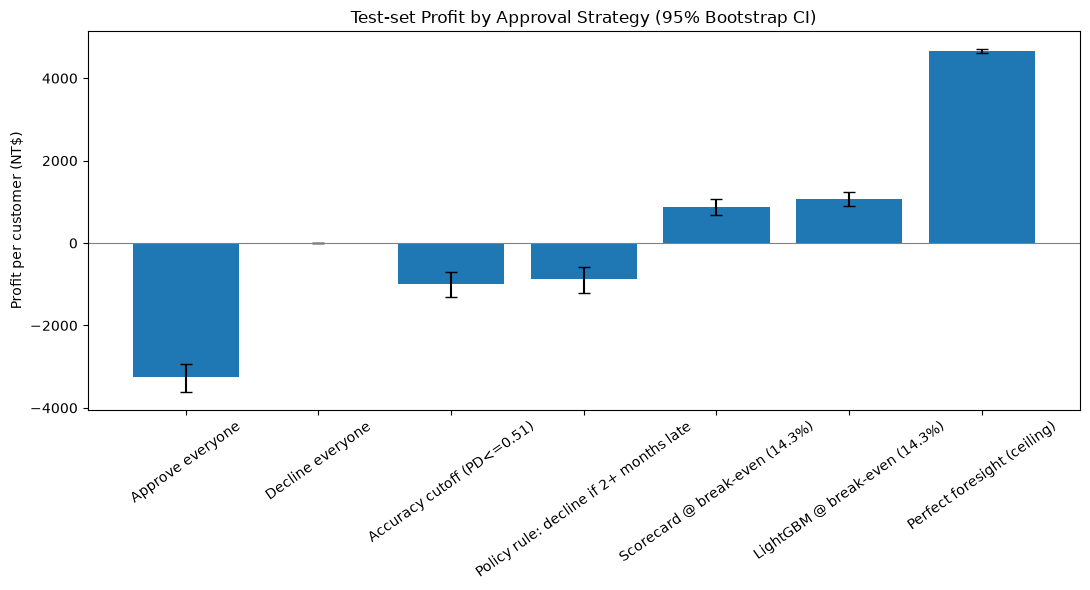

In [20]:
import matplotlib.pyplot as plt
import numpy as np

names = strat.index.tolist()

means = strat.loc[names, "profit_per_customer"].values

lows = np.array([profit_ci.loc[n, "low"] for n in names])
highs = np.array([profit_ci.loc[n, "high"] for n in names])

yerr = np.vstack([
    means - lows,
    highs - means
])

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(names, means, yerr=yerr, capsize=4)

ax.axhline(0, color="grey", linewidth=0.8)

ax.set_ylabel("Profit per customer (NT$)")
ax.set_title("Test-set Profit by Approval Strategy (95% Bootstrap CI)")

ax.tick_params(axis="x", rotation=35)
plt.tight_layout()

plt.savefig(
    "../reports/figures/strategy_profit.png",
    bbox_inches="tight"
)

plt.show()

In [21]:
#Step 9.7 — Money-based calibration check
def exp_vs_real(p, approve):
    exp = ((1 - p) * R - p * L)[approve].sum()
    real = np.where(
        approve,
        realized_profit(y_te, R, L),
        0
    ).sum()

    return exp / len(y_te), real / len(y_te)


for name, p, m in [
    ("Scorecard", p_sc, p_sc <= p_star),
    ("LightGBM", p_gb, p_gb <= p_star)
]:
    e, r = exp_vs_real(p, m)
    print(f"{name}: expected {e:,.0f} vs realized {r:,.0f} per customer")

Scorecard: expected 1,109 vs realized 876 per customer
LightGBM: expected 1,180 vs realized 1,076 per customer


In [22]:
#9.8 — Scenario B: Customer-specific economics
print("bill_avg in X_train:", "bill_avg" in X_train.columns)
print("bill_avg in X_test:", "bill_avg" in X_test.columns)


bill_avg in X_train: True
bill_avg in X_test: True


In [23]:
#9.8A — Calculate training reference statistics
# Reference statistics from TRAIN only

sp_tr = X_train["bill_avg"].clip(lower=0)

bill_tr = train["BILL_AMT1"].clip(lower=0)

ead_tr = bill_tr + 0.2 * (
    train["LIMIT_BAL"] - bill_tr
).clip(lower=0)

ref = {
    "spend_mean": sp_tr.mean(),
    "rmult_mean": (
        sp_tr / sp_tr.mean()
    ).clip(0.25, 3.0).mean(),
    "ead_mean": ead_tr.mean()
}

print("Training reference statistics:")
print(ref)


Training reference statistics:
{'spend_mean': np.float64(44973.92056349206), 'rmult_mean': np.float64(0.9204007158859004), 'ead_mean': np.float64(74643.44514285715)}


In [24]:
#9.8B — Calculate customer-specific revenue and loss
def customer_econ(d_raw, Xf):
    bill = d_raw["BILL_AMT1"].clip(lower=0)

    ead = bill + 0.2 * (
        d_raw["LIMIT_BAL"] - bill
    ).clip(lower=0)

    rmult = (
        Xf["bill_avg"].clip(lower=0) / ref["spend_mean"]
    ).clip(0.25, 3.0)

    R_i = R_flat * rmult / ref["rmult_mean"]
    L_i = L_flat * ead / ref["ead_mean"]

    return R_i.values, L_i.values


# Calculate customer-specific economics
R_tr_i, L_tr_i = customer_econ(train, X_train)
R_te_i, L_te_i = customer_econ(test, X_test)

print(
    "Mean R, L train:",
    R_tr_i.mean().round(0),
    L_tr_i.mean().round(0),
    "| flat:",
    R_flat,
    round(L_flat)
)

Mean R, L train: 6000.0 35855.0 | flat: 6000.0 35855


In [25]:
#9.8C — Check Scenario B on training OOF predictions
# Customer-specific break-even PD for training customers
p_star_tr_i = R_tr_i / (R_tr_i + L_tr_i)

# Apply training OOF predictions
rule_B_sc_tr = oof_sc <= p_star_tr_i
rule_B_gb_tr = oof_gb <= p_star_tr_i

# Evaluate both strategies
compare_B_train = pd.DataFrame({
    "Scorecard, customer-specific": evaluate(
        y_train, rule_B_sc_tr, R_tr_i, L_tr_i
    ),
    "LightGBM, customer-specific": evaluate(
        y_train, rule_B_gb_tr, R_tr_i, L_tr_i
    ),
    "Approve everyone": evaluate(
        y_train,
        np.ones(len(y_train), dtype=bool),
        R_tr_i,
        L_tr_i
    )
}).T

compare_B_train.round(3)

,approval_rate,bad_rate_approved,profit_total,profit_per_customer
"Scorecard, customer-specific",0.458,0.109,3.411330e+07,1624.443
"LightGBM, customer-specific",0.454,0.107,3.471711e+07,1653.196
Approve everyone,1.000,0.221,-4.372908e+07,-2082.337


In [26]:
#9.8D — Test-set evaluation
# Customer-specific break-even PD for test customers
p_star_te_i = R_te_i / (R_te_i + L_te_i)

# Apply test predictions
rule_B_sc = p_sc <= p_star_te_i
rule_B_gb = p_gb <= p_star_te_i

# Compare Scenario A and Scenario B
compare_B = pd.DataFrame({
    "Scorecard, flat cutoff": evaluate(
        y_te, p_sc <= p_star, R_te_i, L_te_i
    ),
    "Scorecard, customer-specific": evaluate(
        y_te, rule_B_sc, R_te_i, L_te_i
    ),
    "LightGBM, customer-specific": evaluate(
        y_te, rule_B_gb, R_te_i, L_te_i
    ),
    "Approve everyone": evaluate(
        y_te,
        np.ones(len(y_te), dtype=bool),
        R_te_i, L_te_i
    )
}).T

compare_B.round(3)


,approval_rate,bad_rate_approved,profit_total,profit_per_customer
"Scorecard, flat cutoff",0.547,0.105,7.903474e+06,878.164
"Scorecard, customer-specific",0.460,0.117,1.116700e+07,1240.778
"LightGBM, customer-specific",0.452,0.107,1.419779e+07,1577.533
Approve everyone,1.000,0.221,-2.175404e+07,-2417.115


In [27]:
#Step 9.9A — Two-way sensitivity grid: revenue × LGD
Rs   = [3000, 4500, 6000, 9000, 12000]
LGDs = [0.5, 0.6, 0.7, 0.8, 0.9]

rows = []

for Rv in Rs:
    for g in LGDs:
        Lv = g * EAD_flat
        ps = Rv / (Rv + Lv)

        base = evaluate(y_te, p_sc <= ps, Rv, Lv)
        fixed = evaluate(y_te, p_sc <= p_star, Rv, Lv)
        allp = evaluate(
            y_te,
            np.ones(len(y_te), bool),
            Rv,
            Lv
        )

        rows.append({
            "R": Rv,
            "LGD": g,
            "p_star": ps,
            "approval": base["approval_rate"],
            "profit_reopt": base["profit_per_customer"],
            "profit_fixed_cut": fixed["profit_per_customer"],
            "regret_of_fixed": (
                base["profit_per_customer"]
                - fixed["profit_per_customer"]
            ),
            "profit_approve_all": allp["profit_per_customer"]
        })

sens = pd.DataFrame(rows)

sens.round(3).head(10)

,R,LGD,p_star,approval,profit_reopt,profit_fixed_cut,regret_of_fixed,profit_approve_all
0,3000,0.5,0.105,0.344,200.113,-3.188,203.301,-3329.307
1,3000,0.6,0.089,0.240,108.396,-297.426,405.822,-4462.435
2,3000,0.7,0.077,0.158,63.865,-591.664,655.529,-5595.563
3,3000,0.8,0.068,0.095,10.032,-885.902,895.933,-6728.692
4,3000,0.9,0.061,0.053,0.458,-1180.139,1180.598,-7861.820
5,4500,0.5,0.149,0.568,715.406,730.812,-15.406,-2161.141
6,4500,0.6,0.128,0.471,515.952,436.574,79.378,-3294.269
7,4500,0.7,0.112,0.387,398.337,142.336,256.001,-4427.397
8,4500,0.8,0.099,0.308,249.075,-151.902,400.976,-5560.525
9,4500,0.9,0.089,0.240,162.593,-446.139,608.733,-6693.653


In [28]:
sens.round(3)


,R,LGD,p_star,approval,profit_reopt,profit_fixed_cut,regret_of_fixed,profit_approve_all
0,3000,0.5,0.105,0.344,200.113,-3.188,203.301,-3329.307
1,3000,0.6,0.089,0.240,108.396,-297.426,405.822,-4462.435
2,3000,0.7,0.077,0.158,63.865,-591.664,655.529,-5595.563
3,3000,0.8,0.068,0.095,10.032,-885.902,895.933,-6728.692
4,3000,0.9,0.061,0.053,0.458,-1180.139,1180.598,-7861.820
5,4500,0.5,0.149,0.568,715.406,730.812,-15.406,-2161.141
6,4500,0.6,0.128,0.471,515.952,436.574,79.378,-3294.269
7,4500,0.7,0.112,0.387,398.337,142.336,256.001,-4427.397
8,4500,0.8,0.099,0.308,249.075,-151.902,400.976,-5560.525
9,4500,0.9,0.089,0.240,162.593,-446.139,608.733,-6693.653


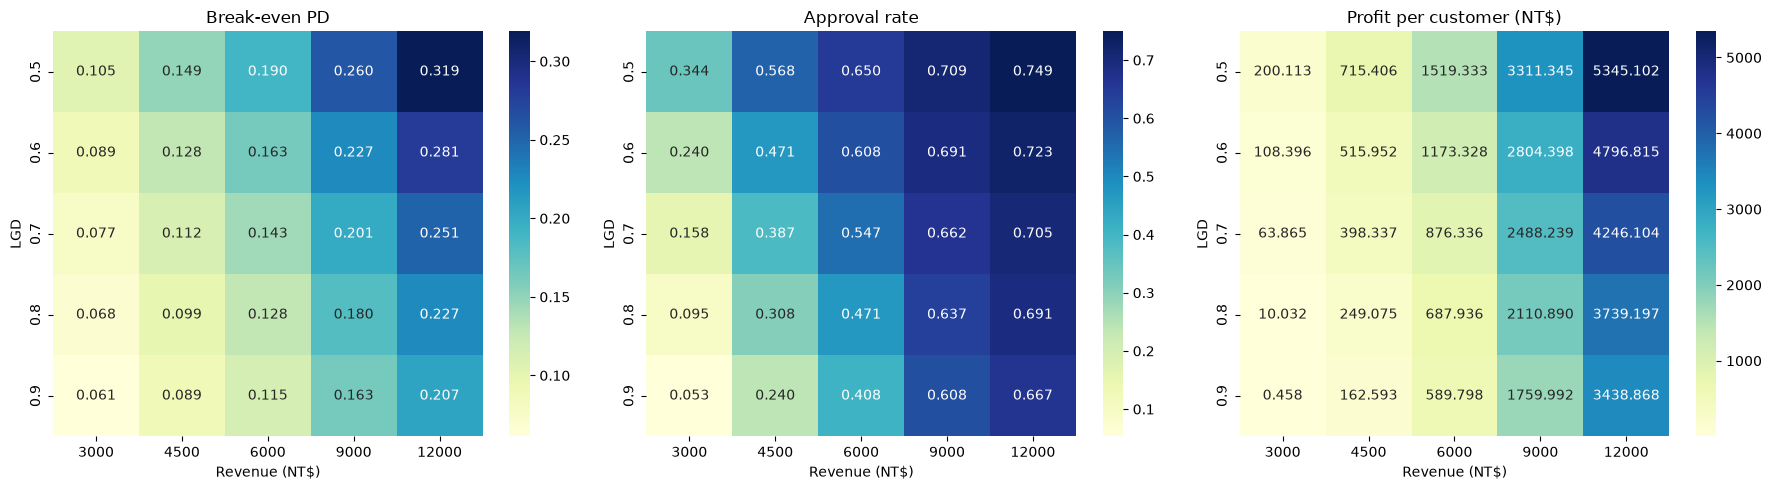

In [29]:
#9.9A — Draw the three sensitivity heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

heatmap_data = [
    ("p_star", "Break-even PD"),
    ("approval", "Approval rate"),
    ("profit_reopt", "Profit per customer (NT$)")
]

for ax, (column, title) in zip(axes, heatmap_data):
    pivot = sens.pivot(
        index="LGD",
        columns="R",
        values=column
    )

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Revenue (NT$)")
    ax.set_ylabel("LGD")

plt.tight_layout()
plt.savefig(
    "../reports/figures/sensitivity_heatmaps.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

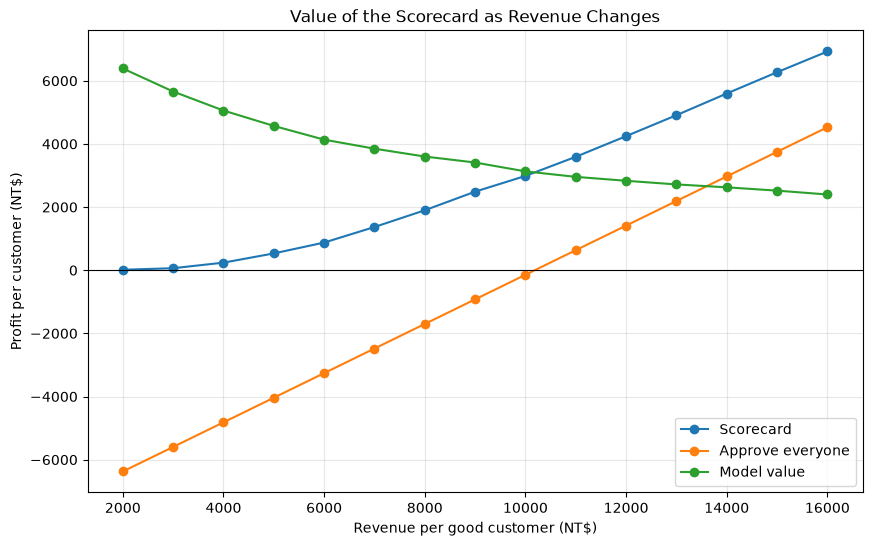

,R,model,approve_all,model_value
0,2000,14.78,-6374.34,6389.12
1,3000,63.87,-5595.56,5659.43
2,4000,240.19,-4816.79,5056.97
3,5000,532.25,-4038.01,4570.26
4,6000,876.34,-3259.23,4135.57
5,7000,1368.88,-2480.45,3849.33
6,8000,1899.10,-1701.67,3600.78
7,9000,2488.24,-922.90,3411.14
8,10000,2986.16,-144.12,3130.28
9,11000,3591.89,634.66,2957.24


In [30]:
rows = []

for Rv in np.arange(2000, 16001, 1000):
    ps = Rv / (Rv + L_flat)

    m = evaluate(
        y_te,
        p_sc <= ps,
        Rv,
        L_flat
    )["profit_per_customer"]

    a = evaluate(
        y_te,
        np.ones(len(y_te), bool),
        Rv,
        L_flat
    )["profit_per_customer"]

    rows.append((Rv, m, a, m - a))

val = pd.DataFrame(
    rows,
    columns=["R", "model", "approve_all", "model_value"]
)

plt.figure(figsize=(10, 6))

plt.plot(val["R"], val["model"], marker="o", label="Scorecard")
plt.plot(val["R"], val["approve_all"], marker="o", label="Approve everyone")
plt.plot(val["R"], val["model_value"], marker="o", label="Model value")

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Revenue per good customer (NT$)")
plt.ylabel("Profit per customer (NT$)")
plt.title("Value of the Scorecard as Revenue Changes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

val.round(2)

In [31]:
#Step 9.9C — Calibration stress test
def shift_odds(p, k):
    o = p / (1 - p) * k
    return o / (1 + o)

rows = []

for k in [0.6, 0.8, 1.0, 1.25, 1.5, 2.0]:
    m = shift_odds(p_sc, k) <= p_star

    r = evaluate(y_te, m, R, L)

    rows.append({
        "odds_multiplier": k,
        "approval": r["approval_rate"],
        "profit_pc": r["profit_per_customer"]
    })

pd.DataFrame(rows).round(3)

,odds_multiplier,approval,profit_pc
0,0.60,0.683,590.158
1,0.80,0.626,800.922
2,1.00,0.547,876.336
3,1.25,0.422,942.181
4,1.50,0.317,822.407
5,2.00,0.158,506.198


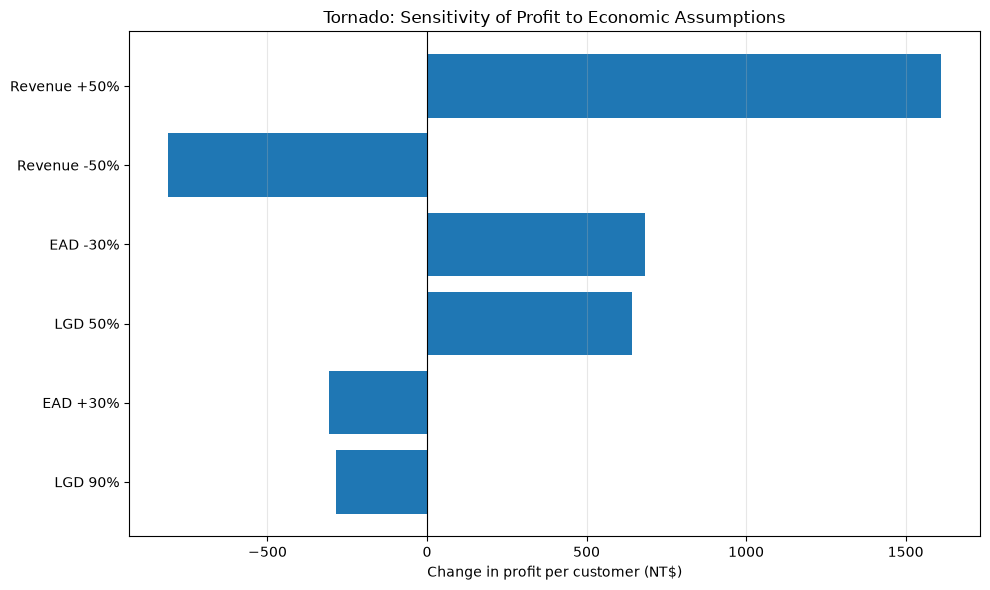

,scenario,profit_per_customer,change_vs_base,absolute_change
3,LGD 90%,589.80,-286.54,286.54
5,EAD +30%,567.89,-308.45,308.45
2,LGD 50%,1519.33,643.00,643.00
4,EAD -30%,1557.98,681.64,681.64
0,Revenue -50%,63.87,-812.47,812.47
1,Revenue +50%,2488.24,1611.90,1611.90


In [32]:
#Step 9.9D — Tornado sensitivity analysis
base_profit = evaluate(
    y_te, p_sc <= p_star, R_flat, L_flat
)["profit_per_customer"]

scenarios = [
    ("Revenue -50%", R_flat * 0.5, LGD * EAD_flat),
    ("Revenue +50%", R_flat * 1.5, LGD * EAD_flat),
    ("LGD 50%", R_flat, 0.5 * EAD_flat),
    ("LGD 90%", R_flat, 0.9 * EAD_flat),
    ("EAD -30%", R_flat, LGD * EAD_flat * 0.7),
    ("EAD +30%", R_flat, LGD * EAD_flat * 1.3)
]

rows = []

for name, Rv, Lv in scenarios:
    ps = Rv / (Rv + Lv)

    result = evaluate(y_te, p_sc <= ps, Rv, Lv)

    rows.append({
        "scenario": name,
        "profit_per_customer": result["profit_per_customer"],
        "change_vs_base": result["profit_per_customer"] - base_profit
    })

tornado = pd.DataFrame(rows)
tornado["absolute_change"] = tornado["change_vs_base"].abs()
tornado = tornado.sort_values("absolute_change")

plt.figure(figsize=(10, 6))

plt.barh(
    tornado["scenario"],
    tornado["change_vs_base"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in profit per customer (NT$)")
plt.title("Tornado: Sensitivity of Profit to Economic Assumptions")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

tornado.round(2)

In [33]:
#Step 9.10A — Champion vs. challenger: money verdict
# Number of customers approved by the scorecard
n_approve = (p_sc <= p_star).sum()

# Scorecard approval decisions
approve_sc_equal = p_sc <= p_star

# Approve the same number using the lowest-risk LightGBM customers
approve_gb_equal = np.zeros(len(p_gb), dtype=bool)
approve_gb_equal[np.argsort(p_gb)[:n_approve]] = True

# Compare realized profit at equal approval rates
equal_approval = pd.DataFrame({
    "Scorecard": evaluate(y_te, approve_sc_equal, R, L),
    "LightGBM": evaluate(y_te, approve_gb_equal, R, L)
}).T

equal_approval.round(3)

,approval_rate,bad_rate_approved,profit_total,profit_per_customer
Scorecard,0.547,0.105,7887025.644,876.336
LightGBM,0.547,0.098,9435656.304,1048.406


In [34]:
#9.10B — Fairness at the profit-optimal cutoff
# Prepare the test groups, following Step 8.9
grp = test[["SEX", "MARRIAGE", "AGE"]].copy()

grp["SEX"] = grp["SEX"].map({
    1: "male",
    2: "female"
})

grp["MARRIAGE"] = grp["MARRIAGE"].map({
    1: "married",
    2: "single",
    3: "other"
})

grp["AGE_BAND"] = pd.cut(
    grp["AGE"],
    [0, 29, 39, 49, 120],
    labels=["<30", "30-39", "40-49", "50+"]
)

# Original Step 8.9 fairness function
def fairness(col, p, approve, min_n=200):
    rows = []

    for g, idx in grp.groupby(col, observed=True).groups.items():
        idx = np.array(list(idx))
        yy = y_te[idx]

        if len(idx) < min_n or yy.min() == yy.max():
            continue

        good, bad = yy == 0, yy == 1

        rows.append({
            "group": g,
            "n": len(idx),
            "default_rate": yy.mean(),
            "mean_PD": p[idx].mean(),
            "calib_gap": p[idx].mean() - yy.mean(),
            "approval_rate": approve[idx].mean(),
            "approval_of_goods": approve[idx][good].mean(),
            "decline_of_bads": (~approve[idx][bad]).mean(),
            "Gini": gini(yy, p[idx])
        })

    t = pd.DataFrame(rows).set_index("group")

    t.loc["ratio min/max approval"] = np.nan
    t.loc["ratio min/max approval", "approval_rate"] = (
        t["approval_rate"].iloc[:-1].min()
        / t["approval_rate"].iloc[:-1].max()
    )

    return t


# Profit-optimal approval decisions
approve_sc = p_sc <= p_star
approve_gb = p_gb <= p_star

# Generate fairness results for both models
fair_sc = {
    c: fairness(c, p_sc, approve_sc)
    for c in ["SEX", "MARRIAGE", "AGE_BAND"]
}

fair_gb = {
    c: fairness(c, p_gb, approve_gb)
    for c in ["SEX", "MARRIAGE", "AGE_BAND"]
}

# Display all six tables
for group in ["SEX", "MARRIAGE", "AGE_BAND"]:
    print("\nSCORECARD:", group)
    display(fair_sc[group].round(3))

    print("\nLIGHTGBM:", group)
    display(fair_gb[group].round(3))


SCORECARD: SEX


,n,default_rate,mean_PD,calib_gap,approval_rate,approval_of_goods,decline_of_bads,Gini
group,,,,,,,,
female,5437.0,0.210,0.215,0.005,0.556,0.634,0.738,0.529
male,3563.0,0.239,0.228,-0.011,0.532,0.619,0.744,0.500
ratio min/max approval,NaN,NaN,NaN,NaN,0.957,NaN,NaN,NaN



LIGHTGBM: SEX


,n,default_rate,mean_PD,calib_gap,approval_rate,approval_of_goods,decline_of_bads,Gini
group,,,,,,,,
female,5437.0,0.210,0.216,0.006,0.517,0.598,0.787,0.571
male,3563.0,0.239,0.228,-0.010,0.486,0.573,0.792,0.545
ratio min/max approval,NaN,NaN,NaN,NaN,0.939,NaN,NaN,NaN



SCORECARD: MARRIAGE


,n,default_rate,mean_PD,calib_gap,approval_rate,approval_of_goods,decline_of_bads,Gini
group,,,,,,,,
married,4133.0,0.239,0.219,-0.020,0.556,0.647,0.731,0.518
single,4756.0,0.207,0.221,0.015,0.539,0.615,0.751,0.524
ratio min/max approval,NaN,NaN,NaN,NaN,0.969,NaN,NaN,NaN


... (2 outputs left out)


SCORECARD: AGE_BAND


,n,default_rate,mean_PD,calib_gap,approval_rate,approval_of_goods,decline_of_bads,Gini
group,,,,,,,,
<30,2882.0,0.224,0.239,0.014,0.507,0.585,0.760,0.523
30-39,3332.0,0.198,0.205,0.006,0.577,0.651,0.725,0.522
40-49,1958.0,0.239,0.215,-0.024,0.568,0.660,0.724,0.509
50+,828.0,0.260,0.230,-0.029,0.513,0.610,0.763,0.497
ratio min/max approval,NaN,NaN,NaN,NaN,0.880,NaN,NaN,NaN



LIGHTGBM: AGE_BAND


,n,default_rate,mean_PD,calib_gap,approval_rate,approval_of_goods,decline_of_bads,Gini
group,,,,,,,,
<30,2882.0,0.224,0.238,0.013,0.463,0.545,0.822,0.567
30-39,3332.0,0.198,0.203,0.004,0.546,0.626,0.778,0.568
40-49,1958.0,0.239,0.218,-0.021,0.508,0.594,0.767,0.556
50+,828.0,0.260,0.238,-0.022,0.478,0.566,0.772,0.526
ratio min/max approval,NaN,NaN,NaN,NaN,0.847,NaN,NaN,NaN


## 9.11 Limitations of the Economic Analysis

1. **Reject inference and selection bias:** The dataset contains customers who already received credit. In a real lending decision, outcomes for rejected applicants are unknown. Models trained only on previously approved customers may therefore be biased.

2. **Behavioral response:** Restricting or freezing a credit line can change customer behaviour. Spending may decrease, and customers may leave. This analysis assumes that a declined customer generates zero revenue and zero loss.

3. **Static, one-period view:** The analysis does not include customer lifetime value, discounting, cost of capital, or time-varying probability of default.

4. **Illustrative revenue and loss assumptions:** Revenue (R) and loss (L) are assumptions rather than observed lender-level economic data. The conclusions depend on the R/L relationship, which was examined through sensitivity analysis.

5. **One-month default window:** The dataset measures default over a short period. This may understate the longer-term risk and profitability considerations relevant to a real lender.

6. **Amex business context:** American Express earns a significant share of revenue through merchant fees on customer spending. Transactors who pay their balances in full may therefore be more valuable than this simplified revenue model captures. Scenario B moves towards a more customer-specific revenue estimate.

7. **Test-set reuse:** The test predictions were used to evaluate multiple strategies and economic scenarios. Although the models were scored once and cutoffs were selected using training out-of-fold predictions, repeated evaluation of the test set should be disclosed as a limitation.

In [35]:
#9.12A — Save the results
# Save the main strategy comparison
strat.to_csv(
    "../reports/strategy_comparison_test.csv"
)

# Save the sensitivity analysis
sens.to_csv(
    "../reports/sensitivity_grid.csv",
    index=False
)

# Save model value versus revenue
val.to_csv(
    "../reports/model_value_vs_revenue.csv",
    index=False
)

# Save Scenario B results
compare_B.to_csv(
    "../reports/scenario_B_customer_specific.csv"
)

# Save the economic assumptions and cutoffs
json.dump(
    {
        "R": R_flat,
        "LGD": LGD,
        "EAD": float(EAD_flat),
        "L": float(L_flat),
        "p_star": float(p_star),
        "score_cutoff": float(score_cut),
        "acc_cutoff": float(t_acc)
    },
    open("../models/economics_config.json", "w"),
    indent=2
)

print("All Step 9 results saved successfully.")

All Step 9 results saved successfully.
